---
---
# CONFIDENCE INTERVALS

---
---

## ROADMAP: where we've been, and where we're going

* When we analyze data, the data is most often based on a **sample** $\mathcal{S}$ taken from a broader **population** $\mathcal{P}$. We think of the sample as a *proxy* for the population.

* Usually interest lies in calculating an **attribute** of the population $a(\mathcal{P})$. 

* But because we don't have access to the population, we instead calculate the attribute in the sample: $a(\mathcal{S})$. We think of the sample attribute $a(\mathcal{S})$ as an **estimate** of the population attribute $a(\mathcal{P})$.

* This is the core of **statistical inference**: we use sample data to draw conclusions about the broader population.

* As we've seen, the quality of inference depends on the quality of the sample. Different samples may yield very different **estimates** of population attributes. This was demonstrated via **sampling distributions**.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/repeated_samples.svg" alt="repeated_resamples" width="300"/>
</div>

* So, when we calculate a sample estimate we need to acknowledge that *it's specific to our sample*, and if we'd had a different sample, we'd have obtained a different estimate. This kind of **sampling variability** needs to be acknowledged and ideally quantified.

* We do this with a **confidence interval**, an interval of numbers that we believe contains the true population attribute. Confidence intervals are reported alongside sample estimates to communicate our uncertainty in the estimate and to provide a broader sense of what the population attribute value might be. 


---
---

## Revisiting Sampling Distributions

Recall the Titanic data which recorded several variables for each of the 2207 passengers and crew members on board the infamous ocean liner the night it sank. Sadly, only 711 (32.2%) of those passengers and crew members survived.

Previously we were interested in *estimating* this survival rate using samples from the full population. Below we take $N=10,000$ samples of $n=100$ passengers/crew from the Titanic and calculate the survival rate in each of those samples. The histogram visualizes all of those estimates. It visualizes the sampling distribution of the survival rate.

In [71]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [72]:
# Read in the data
titanic = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/titanic_passenger_info.csv")

In [73]:
# Take 10,000 samples of size n=100 and calculate the survival rate in each
N = 10000
sample_surv_rates = []
for i in range(N):
    sample = titanic.sample(n=100)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates.append(surv_rate)

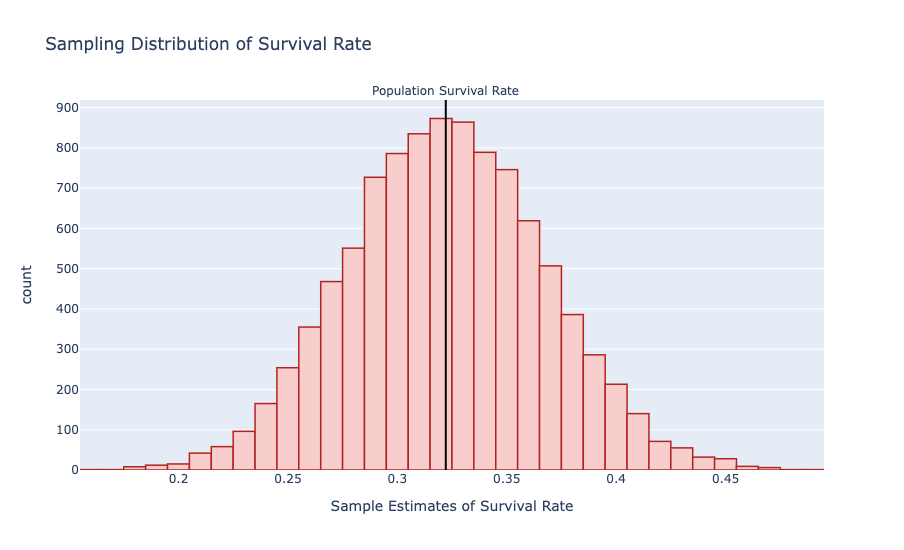

In [74]:
# Visualize the 10,000 sample estimates
sample_surv_rates = pd.Series(sample_surv_rates)
fig = px.histogram(sample_surv_rates,
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = pop_surv_rate,
              line_width=2,            
              line_dash="solid",       
              line_color="black",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

### Interpreting the sampling distribution

**What does this sampling distribution tell us?** 

Previously we drew the following conclusion:
> The "bump" of the histogram is concentrated around the true, population survival rate. This tells us that if you take a sample at random, it's quite likely that you'll get one whose survival rate estimate is close to the population value.

But having now discussed **probability**, we can formalize this insight:
* What's the probability that the survival rate of a randomly selected sample of size $n=100$ lies within $\pm$0.05 of the true population survival rate? 
    * In other words, what's the probability that a randomly selected sample's survival rate lies in the interval 0.32$\pm$0.05 = (0.32-0.05, 0.32+0.05) = (0.27, 0.37)?
    * This is a question of **relative frequency**: among the $N=10,000$ random samples, what proportion of them had survival rates within (0.27, 0.37)?

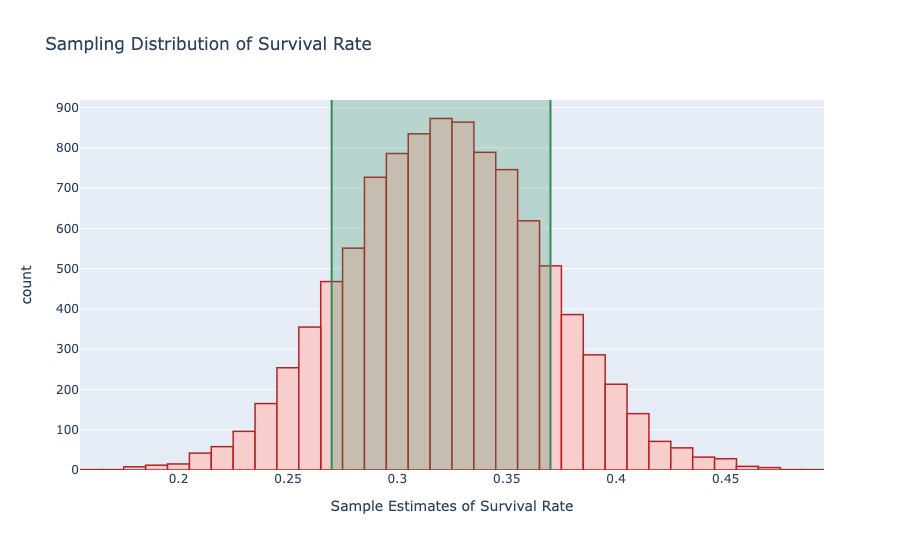

In [75]:
results = pd.DataFrame({"surv rates":sample_surv_rates})
results["event"] = (results["surv rates"] >= 0.27) & (results["surv rates"] <= 0.37)

fig = px.histogram(results, x = "surv rates", color = "event",
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"surv rates":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = 0.27, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vline(x = 0.37, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vrect(x0 = 0.27, x1 = 0.37, fillcolor = "seagreen", opacity = 0.25, line_width = 0)

We answer this question in stages:

1. Translate the event of interest into a logical statement: `(sample_surv_rates >= 0.27) & (sample_surv_rates <= 0.37)`
2. Count how many elements of the resulting boolean series are `True`.
3. The relative frequency is the count from step 2 divided by `N`.

**Note:** we could combine steps 2 and 3 by simply taking the mean of the boolean series.

In [78]:
event = (sample_surv_rates >= 0.27) & (sample_surv_rates <= 0.37)
count = event.sum()
relative_frequency = count / N
print(f"The probability of interest is estimated to be {relative_frequency}")

The probability of interest is estimated to be 0.7765


---

### ACTIVITY 💻: What is the probability a randomly selected sample's survival rate is more than 0.1 from the true population survival rate?

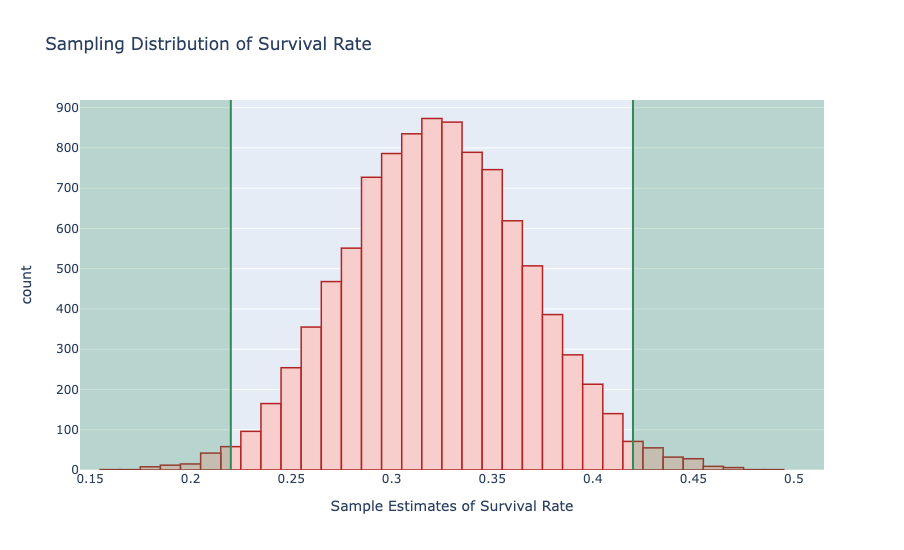

In [76]:
results = pd.DataFrame({"surv rates":sample_surv_rates})
results["event"] = (results["surv rates"] < 0.22) | (results["surv rates"] > 0.42)

fig = px.histogram(results, x = "surv rates", color = "event",
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"surv rates":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vrect(x0 = 0.145, x1 = 0.22, fillcolor = "seagreen", opacity = 0.25, line_width = 0)
fig.add_vrect(x0 = 0.42, x1 = 0.515, fillcolor = "seagreen", opacity = 0.25, line_width = 0)
fig.add_vline(x = 0.22, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vline(x = 0.42, line_width=2, line_dash="solid", line_color="seagreen")

In [77]:
# Calculate the relevant relative frequency here


The probability of interest is estimated to be 0.034


<details>
<summary><b>Show Solution</b></summary>

```python
event = (sample_surv_rates < 0.22) | (sample_surv_rates > 0.42)
relative_frequency = event.mean()
print(f"The probability of interest is estimated to be {relative_frequency}")
```

</details>

---

### Constructing a Confidence Interval

The previous examples each asked a question about probabilities concerning absolute sample error. 
* The first example asked: *what's the probability the absolute sample error is at most 0.05?*
* The second example asked: *what's the probability the absolute sample error is more than 0.1?*

**It's interesting to consider flipping the question.** Instead of choosing a maximal error size (e.g., 0.05) and asking for the probability, we can go the other way. We choose a probability (say, 0.95) and ask:

> How large an error $e$ should we expect, such that 95% of samples have an error at most $e$?

This is just a percentile. The value $e$ is the 95th percentile of the absolute sample errors. We call this the **margin of error**.

In [79]:
sample_errors = sample_surv_rates - pop_surv_rate
e = sample_errors.abs().quantile(0.95)
print(e)

0.0878432260987766


So, 95% of samples are witin 0.0878432260987766 of the truth. Check it:

In [80]:
# Calculate the relevant relative frequency here
event = (sample_surv_rates >= pop_surv_rate - e) & (sample_surv_rates <= pop_surv_rate + e)
count = event.sum()
relative_frequency = count / N
print(f"The probability of interest is estimated to be {relative_frequency}")

The probability of interest is estimated to be 0.9564


<details>
<summary><b>Show Solution</b></summary>

```python
event = (sample_surv_rates >= pop_surv_rate-0.08784) & (sample_surv_rates <= pop_surv_rate+0.08784)
event.mean()
```

</details>

**Now for the key insight:**

The statement

> *the estimate is within $e$ of the truth*

is an equivalent statement to 

> *the truth is within $e$ of the estimate*

So, if we take that latter statement and build an interval around our estimate $$[a(\mathcal{S})-e,~ a(\mathcal{S}) + e],$$ we know that the interval will contain the true, population value whenever our estimate happened to land within $e$ of it. And that happens in 95% of samples!

This gives us an interval we're pretty confident&mdash;95% confident, to be exact&mdash;will contain the true population value. We call this a **95% confidence interval**.

---

### Interpreting a Confidence Interval

**What does it mean to be "95% confident"?**

It means that *if we repeatedly sample the population, each time constructing the confidence interval as described above, 95% of those intervals should contain the true population value*.

Let's check this with the Titanic example. We've already taken $N=10,000$ samples and calculated survival rates on each of them. These are our $\text{estimate}$s. If we add and subtract $e=$ 0.0878432260987766 from each $\text{estimate}$, we will get 10,000 confidence intervals of the form $$[a(\mathcal{S})-e,~a(\mathcal{S}) + e].$$


In [81]:
lower = sample_surv_rates - e
upper = sample_surv_rates + e
intervals = pd.DataFrame({"Lower Confidence Limit":lower,
                         "Upper Confidence Limit":upper})
intervals.head(10)

,Lower Confidence Limit,Upper Confidence Limit
0,0.242157,0.417843
1,0.242157,0.417843
2,0.232157,0.407843
3,0.292157,0.467843
4,0.252157,0.427843
5,0.212157,0.387843
6,0.232157,0.407843
7,0.222157,0.397843
8,0.232157,0.407843
9,0.202157,0.377843


What proportion of these 10,000 confidence intervals contain the true population survival rate 0.3222?

In [82]:
event = (pop_surv_rate >= lower) & (pop_surv_rate <= upper)
event.mean()

0.9564

We call this proportion (0.9564) the **coverage rate** of the confidence intervals in our simulation. This is very close to 0.95, and the relative frequency definition of probability tells us it will get closer and closer to 0.95 as we increase $N$.

To reinforce the idea of coverage, consider the graphic below in which 20 samples and hence 20 confidence intervals were obtained.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/coverage1.svg" alt="repeated_resamples" width="300"/>
</div>

The coverage rate measures the proportion of intervals that contain, or **cover** the true population attribute. Not all of them will, but if they're all 95% confidence intervals, *roughly* 95% of them should.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/coverage2.svg" alt="repeated_resamples" width="300"/>
</div>

**So, when we construct a $\boldsymbol{C\%}$ confidence interval, and we say we're $\boldsymbol{C\%}$ confident it contains the true population attribute, what we mean is:**

> *$C\%$ of confidence intervals constructed in this way should cover the true population attribute*.

---

### The Problem with this Interval

We have developed a way to construct a confidence interval: 
* Take a sample.
* Calculate an estimate of the population attribute with that sample.
* Add and subtract the margin of error $e$ from that estimate.

If we do this, we can be confident (with some particular **confidence level**) that the interval will contain the true population value.

**HOWEVER**

The margin of error $e$ was a percentile of the absolute sample errors. This is a problem. In order to perform this calculation we needed 

1. many samples, and
2. the population attribute value.

In practice, we have neither of these. So, what do we do? We need to try to approximate the sampling distribution with out single sample.

---
---

## The Bootstrap: A Proxy for Sampling Distributions

In order to construct a confidence interval, it would be ideal to repeatedly sample the population $\mathcal{P}$. **But we can't**. In practice, we have *just one sample* $\mathcal{S}$.

To get around this problem, we do something called **resampling**. The idea is to repeatedly sample $\mathcal{S}$ as if it were $\mathcal{P}$. The intuition is as follows:
* We want to repeatedly sample $\mathcal{P}$, but we can't.
* We have access only to $\mathcal{S}$, but we think of it as an esimate of $\mathcal{P}$. Recall, $\mathcal{S}=\hat{\mathcal{P}}$.
* Since $\mathcal{S}$ is our best guess of $\mathcal{P}$, we will simply treat $\mathcal{S}$ as if it were $\mathcal{P}$
* So, rather than repeatedly sampling $\mathcal{P}$, we repeatedly sample $\mathcal{S}$.

The graphic below visualizes this process. Contrast this image with the one included at the top of the notes.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/repeated_resamples.svg" alt="repeated_resamples" width="300"/>
</div>


It's very important to consider *how* the **resamples** $\mathcal{S}_1^*, \mathcal{S}_2^*, \ldots, \mathcal{S}_B^*$ are taken. Ideally we would mimic the process by which $\mathcal{S}$ was taken from $\mathcal{P}$ (e.g., simple random samples of size $n$). 

But how do we randomly sample $n$ units from a collection of $n$ units? 
* It would seem that the resamples would be the same each time, and always equal to the original sample. That is of course unhelpful. 
* To overcome this problem, we **sample *with* replacement**. This means that before selecting another unit, you replace the you selected back into the collection you are drawing from. 
* The consequence of this is that you may select the same unit more than once.

Below we use the `numpy` random integer selector to illustrate this idea.

In [69]:
# Run this cell several times. Do you get duplicate numbers?
np.random.randint(low = 1, high = 11, size = 5)

array([8, 8, 2, 2, 5])

This procedure, where we repeatedly resample our original sample *with replacement*, is what is known as **the bootstrap**.

The collection of attribute values calculated over the bootstrap resamples $a(\mathcal{S}_1^*),a(\mathcal{S}_1^*),\ldots, a(\mathcal{S}_B^*)$ is called the **bootstrap distribution** and it provides a single-sample approximation to the sampling distribution of $a(\mathcal{S})$.

---

### Approximating a Sampling Distribution

Let's try the bootstrap procedure described above using the Titanic data. In particular, let's take one sample of size $n=100$, and resample that with replacement many times and examine the survival rate estimates we calculate on each of the resamples.



In [60]:
# Take a sample if size n=100
S = titanic.sample(n=100)
S["survived"].value_counts(normalize = True).get("yes")

0.34

To take a "resample", we will sample `S` defined above using the `.sample()` method again, but this time adding the argument `replace = True`.

In [61]:
S_star = S.sample(n=100, replace=True)
print(S_star)

      gender   age             class     embarked        country      fare  \
1010    male   8.0               3rd   Queenstown        Ireland   29.0206   
1284    male  27.0               1st  Southampton  United States  211.1000   
992   female  33.0               2nd  Southampton            NaN   26.0000   
151     male  32.0               2nd  Southampton            NaN   13.0000   
1794    male  20.0  victualling crew  Southampton        England    0.0000   
...      ...   ...               ...          ...            ...       ...   
1603    male  45.0  victualling crew      Belfast        England    0.0000   
1152    male  33.0               3rd    Cherbourg        Croatia    8.1309   
260   female  23.0               3rd   Queenstown        Ireland    7.1500   
1797    male  25.0         deck crew  Southampton        England    0.0000   
721     male  42.0               1st  Southampton         Sweden   26.1100   

      sibsp  parch survived  
1010    4.0    1.0       no  
128

Let's now do that *many* times. Specifically $B=10,000$ times, each time calculating the survival rate on the resamples. These $B$ survival rates constitute the bootstrap distribution.

In [62]:
# Take 10,000 resamples of size n=100 (with replacement) from our original sample and calculate the survival rate in each
B = 10000
resample_surv_rates = []
for b in range(B):
    resample = S.sample(n=100, replace=True)
    surv_rate = resample["survived"].value_counts(normalize = True).get("yes", 0)
    resample_surv_rates.append(surv_rate)

Next we visualize the bootstrap distribution of the survival rate.

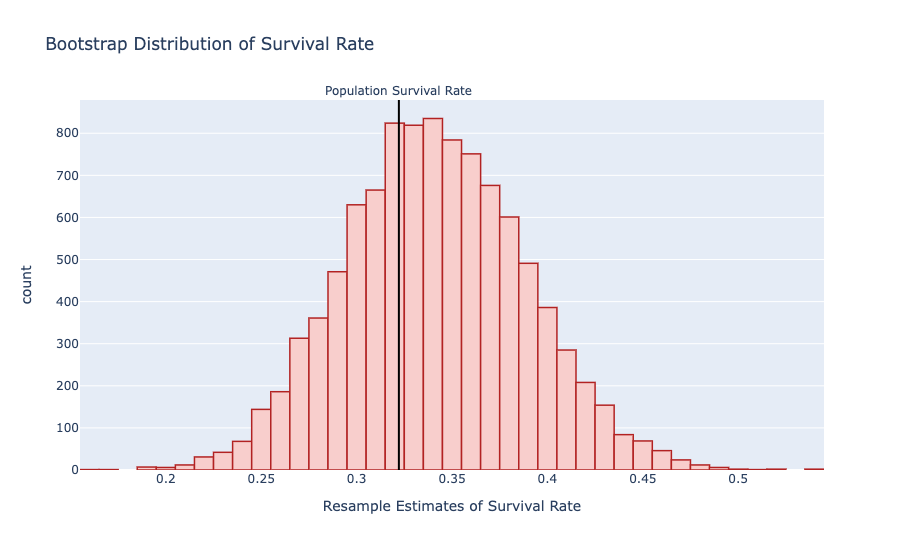

In [63]:
# Visualize the 10,000 sample estimates
resample_surv_rates = pd.Series(resample_surv_rates)
fig = px.histogram(resample_surv_rates,
                   title = "Bootstrap Distribution of Survival Rate",
                   labels = {"value":"Resample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = pop_surv_rate,
              line_width=2,            
              line_dash="solid",       
              line_color="black",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

Generally speaking, **we've constructed something very similar to the sampling distribution, but with just one sample!**

Contrast this with the sampling distribution histogram we constructed above and explore their similarities and differences

* The shape is similar
* The spread is similar
* The center is shifted slightly

In [64]:
print(f"St. Dev. of Sampling Distribution of Survival Rates:  {np.std(sample_surv_rates)}")
print(f"St. Dev. of Bootstrap Distribution of Survival Rates: {np.std(resample_surv_rates)}")

St. Dev. of Sampling Distribution of Survival Rates:  0.04568788005587477
St. Dev. of Bootstrap Distribution of Survival Rates: 0.0473584621371936


In [65]:
print(f"Mean of Sampling Distribution of Survival Rates:  {np.mean(sample_surv_rates)}")
print(f"Mean of Bootstrap Distribution of Survival Rates: {np.mean(resample_surv_rates)}")

Mean of Sampling Distribution of Survival Rates:  0.322204
Mean of Bootstrap Distribution of Survival Rates: 0.341008


**Questions:** 
* Why is the center shifted? 
* Does it matter?

---

### Bootstrap Sample Error

Recall, **sample error** is defined as $$\text{sample error} = a(\mathcal{S})-a(\mathcal{P}).$$

We can perform a similar calculation in this context, noting that we're now treating $\mathcal{S}$ as if it were $ \mathcal{P}$ and likewise $\mathcal{S}^*$ as if it were $\mathcal{S}$.

We thus define **bootstrap sample error** as $$\text{bootstrap sample error} = a(\mathcal{S}^*)-a(\mathcal{S}).$$

Remember that in the confidence interval defined previously $$[a(\mathcal{S})-e, ~a(\mathcal{S}) + e],$$ the margin of error $e$ was a percentile of the absolute sample errors. 
* In practice we cannot know the true sample errors, but we can estimate them with bootstrap sample errors. 
* We can therefore also estimate the margin of error $e$ as a percentile of the absolute bootstrap sample errors. We will call the bootstrap margin of error $e^*$.

In the previous example we found $e$ as follows:

In [20]:
sample_errors = sample_surv_rates - pop_surv_rate
e = sample_errors.abs().quantile(0.95)
print(e)

0.0878432260987766


The analogous calculation using the bootstrap sample errors is as follows:

In [21]:
resample_errors = resample_surv_rates - S["survived"].value_counts(normalize = True).get("yes")
e_star = resample_errors.abs().quantile(0.95)
print(e_star)

0.09000000000000002


Despite the shift in the bootstrap distribution relative to the sampling distribution, there is good agreement between the percentile of the true sample error distribution and bootstrap sample error distribution.

This gives a tool for constructing confidence intervals when you have just one sample.

---

### The Percentile Method Confidence Interval

We have seen that a $C\%$ confidence interval can be constructed as $$[a(\mathcal{S})-e, ~a(\mathcal{S}) + e],$$ where $e$ is the $C^\text{th}$ percentile of the absolute sample error distribution. Unfortunately, knowing $e$ is impossible with only one sample. 

However, we've now seen we can estimate $e$ using the bootstrap, which suggests we should be able calculate the confidence interval as $$[a(\mathcal{S})-e^*, a(\mathcal{S}) + e^*],$$ where $e^*$ is the $C^\text{th}$ percentile of the absolute bootstrap sample errors.

Let's calculate this interval for the single sample we took at the beginning of this section.

In [24]:
sample_surv_rate = S["survived"].value_counts(normalize = True).get("yes")
print(f"lower confidence limit: {sample_surv_rate - e_star}")
print(f"upper confidence limit: {sample_surv_rate + e_star}")

lower confidence limit: 0.25999999999999995
upper confidence limit: 0.44


**Questions:**

* So the 95% confidence interval is (0.26, 0.44). What conclusion should we make?

* How did we do? Did the confidence interval capture the true survival rate?

* How often should we expect such a confidence interval to contain the true population attribute value?

#### An Even Easier&mdash;and More General&mdash;Calculation

It turns out that when the bootstrap distribution is symmetric, the confidence interval calculation above yields exactly the same thing as if you directly calculate relevant percentiles of the bootstrap distribution itself. 

In particular, if $a(\mathcal{S}_1^*),a(\mathcal{S}_1^*),\ldots, a(\mathcal{S}_B^*)$ are your bootstrap estimates of the attribute of interest, their $(100-C)/2$ percentile will give you the same lower confidence limit as above. And their $(100+C)/2$ percentile will give you the same upper confidence limit as above.

Observe:

In [25]:
C = 95
print(f"lower confidence limit: {np.percentile(resample_surv_rates, (100-C)/2)}")
print(f"upper confidence limit: {np.percentile(resample_surv_rates, (100+C)/2)}")

lower confidence limit: 0.26
upper confidence limit: 0.44


**However:** if the bootstrap distribution **is not symmetric** these two methods of calculating the confidence interval *will not* agree. In that case, which approach is better?

**The latter method, in which we calculate percentiles of the bootstrap distribution directly, is to be preferred.**
* It's a simpler calculation.
    * It eliminates the need to calculate absolute errors, so it requires fewer lines of code.
* It's more flexible. 
    * It accommodates both symmetric and skewed bootstrap distributions.
* The endpoints of the confidence interval will always be realistic values the attribute *could* take on.
    * If the margin of error is very large, $a(\mathcal{S})- e^*$ or $a(\mathcal{S})+ e^*$ may lie beyond what is possible. For instance, survival rate must be between 0 and 1. It's possible with a large margin of error, $a(\mathcal{S})- e^*$ may be a negative number or $a(\mathcal{S})+ e^*$ may be larger than 1. 

The latter method, in which we calculate percentiles of the bootstrap distribution directly, is what is referred to as the **percentile method** for bootstrap confidence intervals. Specifically, a $C\%$ percentile method confidence interval for population attribute $a(\mathcal{P})$ is:
* Lower confidence limit: the $(100-C)/2$ percentile of $\{a(\mathcal{S}_1^*),a(\mathcal{S}_1^*),\ldots, a(\mathcal{S}_B^*)\}$
* Upper confidence limit: the $(100+C)/2$ percentile of $\{a(\mathcal{S}_1^*),a(\mathcal{S}_1^*),\ldots, a(\mathcal{S}_B^*)\}$

---

#### ACTIVITY 💻: Calculate a 95% percentile method confidence interval for average age.

<details>
<summary><b>Show Solution</b></summary>

```python
B = 10000
resample_avg_age = []

for i in range(B):
    resample = S.sample(n=100, replace=True)
    avg_age = resample["age"].mean()
    resample_avg_age.append(avg_age)

np.percentile(resample_avg_age, [2.5, 97.5])
```

</details>


---
#### ACTIVITY 💻: Calculate a 95% percentile method confidence interval for median age.

<details>
<summary><b>Show Solution</b></summary>

```python
B = 10000
resample_med_age = []

for i in range(B):
    resample = S.sample(n=100, replace=True)
    med_age = resample["age"].median()
    resample_med_age.append(med_age)

np.percentile(resample_med_age, [2.5, 97.5])
```

</details>

---

#### ACTIVITY 💻: Calculate a 95% percentile method confidence interval for the standard deviation of age.

<details>
<summary><b>Show Solution</b></summary>

```python
B = 10000
resample_std_age = []

for i in range(B):
    resample = S.sample(n=100, replace=True)
    std_age = resample["age"].std()
    resample_std_age.append(std_age)

np.percentile(resample_std_age, [2.5, 97.5])
```

</details>

---

### Interpreting the Percentile Method Confidence Interval

Previously, we saw that a 95% confidence interval should cover the true population attribute value 95% of the time, under repeated sampling. 

* However, we checked this in an unrealistic setting (where we had access to the whole population). 
* Will we find this property still holds when we check it with percentile method confidence intervals based on bootstrapping a single sample?

Let's check...

1. To calculate coverage we need $N$ samples to obtain $N$ confidence intervals. 
2. Each confidence interval is calculated by bootstrapping the corresponding sample $B$ times, yielding $B$ survival rates, whose 2.5th and 97.5th percentiles we calculate. These percentiles define the confidence interval for that sample.
3. Ultimately we check what proportion of the $N$ confidence intervals cover the true population survival rate.

Steps 1 and 2 require nested `for` loops: we need to draw many samples, and for each sample we need to draw many resamples. So this will be very computationally intensive if $N$ and $B$ are both large. For illustration, we take $N=100$ samples and calculate percentile method confidence intervals by resampling each $B=1000$ times. 

If you don't mind waiting around, you can increase these numbers in the code below and re-run the cell.

In [95]:
N = 100
B = 1000
lower_limits = []
upper_limits = []

for i in range(N):
    S = titanic.sample(n=100)
    resample_surv_rates = []
    for b in range(B):
        resample = S.sample(n=100, replace=True)
        surv_rate = resample["survived"].value_counts(normalize = True).get("yes", 0)
        resample_surv_rates.append(surv_rate)
    lower_limits.append(np.percentile(resample_surv_rates, 2.5))
    upper_limits.append(np.percentile(resample_surv_rates, 97.5))
    
cover = (pop_surv_rate >= lower_limits) &  (pop_surv_rate <= upper_limits)
cover.mean()

0.93

We see that the coverage rate is very close to the nominal 0.95 we would expect. This is encouraging&mdash;it suggests that we can interpret the percentile method confidence intervals in the same way we learned to before.

**When we construct a $\boldsymbol{C\%}$ percentile method confidence interval, and we say we're $\boldsymbol{C\%}$ confident it contains the true population attribute, what we mean is:**

> *$C\%$ of confidence intervals constructed in this way should cover the true population attribute*.

---
---

## Where We Go From Here

A **confidence interval** gives us information about the value of the population attribute.

* It gives us a range of *plausible* values that it might be.

* Implicitly, this also tells us what values it's *unlikely* to be. 

* When we took a sample of size $n=100$ from the Titanic data, we calculated the 95% confidence interval to be (0.26, 0.44). This tells us that the true survival rate is plausibly something between 0.26 and 0.44. On the other hand, it also suggests a survival rate of 0.7 (for example) is quite unlikely, as this lies outside the interval.

Another statistical tool for determining what value(s) of a population attribute are plausible is **hypothesis testing**. That's where we head next.

---
---

##